<a href="https://colab.research.google.com/github/rahuldevagiri/deep-learning-project/blob/main/02_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 5.1: setup

In [ ]:
!pip install -q segmentation-models-pytorch
import os, json, glob, random, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from matplotlib.colors import ListedColormap
from google.colab import drive
drive.mount("/content/drive")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

Mounted at /content/drive
Device: cuda Tesla T4


Cell 5.2a: build the zip on Drive. Run this once only

In [ ]:
SRC = "/content/drive/MyDrive/lulc_s1_global"
n_drive = len(glob.glob(f"{SRC}/patches/*/*.npz"))
print("files on Drive:", n_drive)            # expect 1740

if not os.path.exists(f"{SRC}/patches.zip"):
    !cd "{SRC}" && zip -q -r -0 /content/patches.zip patches
    !unzip -l /content/patches.zip | tail -1
    !cp /content/patches.zip "{SRC}/patches.zip"
!ls -lh "{SRC}/patches.zip"

files on Drive: 1740
4024065141                     1744 files
-rw------- 1 root root 3.8G Oct 26 21:33 /content/drive/MyDrive/lulc_s1_global/patches.zip


Cell 5.2b: run this every session. It replaces the old 5.2.

In [ ]:
SRC, DATA = "/content/drive/MyDrive/lulc_s1_global", "/content/data"
os.makedirs(DATA, exist_ok=True)

if len(glob.glob(f"{DATA}/patches/*/*.npz")) < 1740:
    !rm -rf "{DATA}/patches"
    !cp "{SRC}/patches.zip" /content/patches.zip
    !unzip -q -o /content/patches.zip -d "{DATA}/"
    !rm /content/patches.zip
!cp "{SRC}/index.csv" "{SRC}/norm_stats.json" "{DATA}/"

n_local = len(glob.glob(f"{DATA}/patches/*/*.npz"))
idx = pd.read_csv(f"{DATA}/index.csv")
idx["path"] = idx.path.str.replace(SRC, DATA, regex=False)
missing = (~idx.path.map(os.path.exists)).sum()
stats = json.load(open(f"{DATA}/norm_stats.json"))
CLASSES, COLORS = stats["classes"], stats["colors"]
NC = len(CLASSES)

print("local files:", n_local, "| index rows:", len(idx), "| missing:", missing)
print(idx.split.value_counts())
assert n_local == 1740 and missing == 0, "Copy incomplete - rerun this cell"

local files: 1740 | index rows: 20575 | missing: 0
split
train    14827
val       3070
test      2678
Name: count, dtype: int64


Cell 5.3: preprocessing and the Dataset

In [ ]:
def preprocess(x2, stats):
    """x2: (2, H, W) int16 dB*100 [VV, VH] -> (3, H, W) float32 normalized, nodata mask."""
    nod = (x2[0] == stats["nodata"]) | (x2[1] == stats["nodata"])
    vv = np.clip(x2[0] / stats["scale"], *stats["clip"]["VV"])
    vh = np.clip(x2[1] / stats["scale"], *stats["clip"]["VH"])
    img = np.stack([vv, vh, vv - vh]).astype(np.float32)
    mean = np.array(stats["mean"], np.float32)[:, None, None]
    std = np.array(stats["std"], np.float32)[:, None, None]
    img = (img - mean) / std
    img[:, nod] = 0.0
    return img, nod

class S1Dataset(Dataset):
    def __init__(self, df, stats, augment=False):
        self.df, self.stats, self.augment = df.reset_index(drop=True), stats, augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        d = np.load(r.path)
        img, nod = preprocess(d["x"][r.month], self.stats)
        y = d["y"].astype(np.int64)
        y[nod] = 255                                   # ignore gaps
        if self.augment:                               # geometry only, no value changes
            k = random.randint(0, 3)
            img, y = np.rot90(img, k, (1, 2)), np.rot90(y, k)
            if random.random() < 0.5:
                img, y = img[:, :, ::-1], y[:, ::-1]
        return torch.from_numpy(img.copy()), torch.from_numpy(y.copy())

ds = {s: S1Dataset(idx[idx.split == s], stats, augment=(s == "train")) for s in ("train", "val", "test")}
BS = 16
dl = {s: DataLoader(ds[s], batch_size=BS, shuffle=(s == "train"), num_workers=2,
                    pin_memory=True, drop_last=(s == "train")) for s in ds}
print({s: len(ds[s]) for s in ds})

{'train': 14827, 'val': 3070, 'test': 2678}


Cell 5.4: sanity check a batch

batch load: 1.71 s
x torch.Size([16, 3, 256, 256]) torch.float32 mean/std per ch: [ 0.07  0.16 -0.19] [0.86 0.82 0.92]
y torch.Size([16, 256, 256]) torch.int64 values: [0, 1, 2, 3, 4, 5, 6, 255]


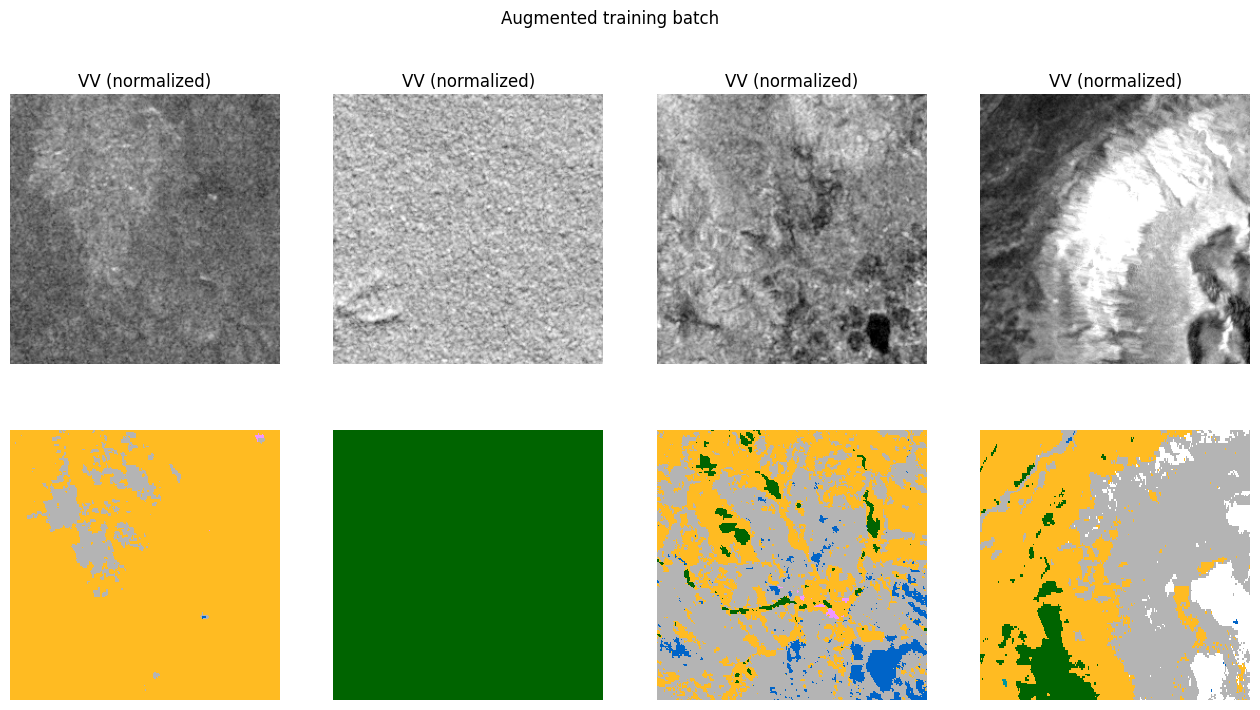

In [ ]:
t0 = time.time()
xb, yb = next(iter(dl["train"]))
print("batch load:", round(time.time() - t0, 2), "s")
print("x", xb.shape, xb.dtype, "mean/std per ch:", xb.mean((0, 2, 3)).numpy().round(2), xb.std((0, 2, 3)).numpy().round(2))
print("y", yb.shape, yb.dtype, "values:", torch.unique(yb).tolist())

cmap = ListedColormap(COLORS)
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for k in range(4):
    ax[0, k].imshow(xb[k, 0], cmap="gray", vmin=-2, vmax=2); ax[0, k].set_title("VV (normalized)")
    ax[1, k].imshow(np.ma.masked_equal(yb[k].numpy(), 255), cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest")
for a in ax.ravel(): a.axis("off")
plt.suptitle("Augmented training batch"); plt.show()

Cell 5.5: build the model and test a forward pass


In [ ]:
model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet",
                 in_channels=3, classes=NC).to(DEVICE)
print("params (M):", round(sum(p.numel() for p in model.parameters()) / 1e6, 1))

with torch.no_grad():
    out = model(xb.to(DEVICE))
print("output:", out.shape)   # expect (16, 7, 256, 256)

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

params (M): 24.4
output: torch.Size([16, 7, 256, 256])


5.6: build the fast cache

In [ ]:
CACHE = "/content/cache"; os.makedirs(CACHE, exist_ok=True)
idx = idx.reset_index(drop=True)
paths = sorted(idx.path.unique())
pid = {p: i for i, p in enumerate(paths)}
idx["pid"] = idx.path.map(pid)

if not os.path.exists(f"{CACHE}/done"):
    X = np.lib.format.open_memmap(f"{CACHE}/X.npy", mode="w+", dtype=np.int16,
                                  shape=(len(idx), 2, 256, 256))
    Y = np.zeros((len(paths), 256, 256), np.uint8)
    for p, g in tqdm(idx.groupby("path")):
        d = np.load(p); x = d["x"]
        Y[pid[p]] = d["y"]
        for row, m in zip(g.index, g.month):
            X[row] = x[m]
    X.flush(); del X
    np.save(f"{CACHE}/Y.npy", Y)
    open(f"{CACHE}/done", "w").close()
!ls -lh {CACHE}

  0%|          | 0/1724 [00:00<?, ?it/s]

total 5.2G
-rw-r--r-- 1 root root    0 Oct 26 22:54 done
-rw-r--r-- 1 root root 5.1G Oct 26 22:54 X.npy
-rw-r--r-- 1 root root 108M Oct 26 22:54 Y.npy


New cell 5.7: fast Dataset and DataLoaders

In [ ]:
class S1Fast(Dataset):
    def __init__(self, rows, stats, augment=False):
        self.rows, self.pids = rows.index.to_numpy(), rows.pid.to_numpy()
        self.stats, self.augment, self.X, self.Y = stats, augment, None, None

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        if self.X is None:                                  # open lazily inside each worker
            self.X = np.load(f"{CACHE}/X.npy", mmap_mode="r")
            self.Y = np.load(f"{CACHE}/Y.npy", mmap_mode="r")
        img, nod = preprocess(np.asarray(self.X[self.rows[i]]), self.stats)
        y = self.Y[self.pids[i]].astype(np.int64)
        y[nod] = 255
        if self.augment:
            k = random.randint(0, 3)
            img, y = np.rot90(img, k, (1, 2)), np.rot90(y, k)
            if random.random() < 0.5:
                img, y = img[:, :, ::-1], y[:, ::-1]
        return torch.from_numpy(img.copy()), torch.from_numpy(y.copy())

ds = {s: S1Fast(idx[idx.split == s], stats, augment=(s == "train")) for s in ("train", "val", "test")}
dl = {s: DataLoader(ds[s], batch_size=BS, shuffle=(s == "train"), num_workers=2,
                    pin_memory=True, drop_last=(s == "train"),
                    persistent_workers=True, prefetch_factor=4) for s in ds}

t0 = time.time()
for k, (xb, yb) in enumerate(dl["train"]):
    if k == 20: break
print(f"20 batches: {time.time() - t0:.1f}s  ->  approx {(time.time() - t0) / 20 * len(dl['train']) / 60:.1f} min/epoch data time")

20 batches: 1.3s  ->  approx 1.0 min/epoch data time


Step 6: Training

Cell 6.1: loss and metrics

In [ ]:
from tqdm.auto import tqdm
CKPT_DIR = f"{SRC}/models"; os.makedirs(CKPT_DIR, exist_ok=True)
EPOCHS, LR = 30, 3e-4

w = torch.tensor(stats["class_weights"], dtype=torch.float32, device=DEVICE)
ce = nn.CrossEntropyLoss(weight=w, ignore_index=255)
dice = smp.losses.DiceLoss(mode="multiclass", ignore_index=255)
def loss_fn(logits, y):
    return ce(logits, y) + dice(logits, y)

def update_cm(cm, logits, y):
    pred, m = logits.argmax(1), y != 255
    cm += torch.bincount(y[m] * NC + pred[m], minlength=NC * NC).reshape(NC, NC)
    return cm

def metrics_from_cm(cm):
    cm = cm.double(); tp = cm.diag()
    iou = tp / (cm.sum(0) + cm.sum(1) - tp).clamp(min=1)
    return {"miou": iou.mean().item(), "acc": (tp.sum() / cm.sum()).item(), "iou": iou.cpu().numpy()}

Cell 6.2: one epoch (used for both train and val)

In [ ]:
def run_epoch(model, loader, train, opt=None, scaler=None):
    model.train(train)
    cm = torch.zeros(NC, NC, dtype=torch.long, device=DEVICE)
    tot, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in tqdm(loader, leave=False):
            xb = xb.to(DEVICE, non_blocking=True, memory_format=torch.channels_last)   # changed
            yb = yb.to(DEVICE, non_blocking=True)                                       # changed
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(xb)
            loss = loss_fn(out.float(), yb)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(opt); scaler.update()
            tot += loss.item() * xb.size(0); n += xb.size(0)
            cm = update_cm(cm, out.detach(), yb)
    m = metrics_from_cm(cm); m["loss"] = tot / n
    return m

Cell 6.3: model, optimizer, resume

In [ ]:
model = smp.Unet("resnet34", encoder_weights="imagenet", in_channels=3, classes=NC).to(DEVICE).to(memory_format=torch.channels_last)   # changed
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS, eta_min=1e-6)
scaler = torch.amp.GradScaler("cuda")

start, best, hist = 0, 0.0, []
LAST, BEST = f"{CKPT_DIR}/last.pth", f"{CKPT_DIR}/best.pth"
if os.path.exists(LAST):
    ck = torch.load(LAST, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
    sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start, best, hist = ck["epoch"] + 1, ck["best"], ck["hist"]
print(f"start epoch {start + 1}/{EPOCHS} | best val mIoU so far {best:.3f}")

start epoch 2/30 | best val mIoU so far 0.371


Cell 6.4: training loop

In [ ]:
for ep in range(start, EPOCHS):
    t0 = time.time()
    tr = run_epoch(model, dl["train"], True, opt, scaler)
    va = run_epoch(model, dl["val"], False)
    sched.step()

    hist.append({"epoch": ep + 1, "lr": opt.param_groups[0]["lr"],
                 "train_loss": tr["loss"], "val_loss": va["loss"],
                 "train_miou": tr["miou"], "val_miou": va["miou"], "val_acc": va["acc"],
                 **{f"iou_{c}": float(v) for c, v in zip(CLASSES, va["iou"])}})
    is_best = va["miou"] > best
    if is_best:
        best = va["miou"]
        torch.save({"model": model.state_dict(), "stats": stats, "arch": "Unet", "encoder": "resnet34",
                    "epoch": ep + 1, "val_miou": best}, BEST)
    torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                "scaler": scaler.state_dict(), "epoch": ep, "best": best, "hist": hist}, LAST)
    pd.DataFrame(hist).to_csv(f"{CKPT_DIR}/history.csv", index=False)

    print(f"ep {ep + 1:02d} | {time.time() - t0:4.0f}s | "
          f"train loss {tr['loss']:.3f} mIoU {tr['miou']:.3f} | "
          f"val loss {va['loss']:.3f} mIoU {va['miou']:.3f} acc {va['acc']:.3f}"
          + ("  *best" if is_best else ""))

  0%|          | 0/926 [00:00<?, ?it/s]

  0%|          | 0/192 [00:00<?, ?it/s]

ep 02 |  138s | train loss 1.613 mIoU 0.419 | val loss 1.570 mIoU 0.435 acc 0.596  *best


  0%|          | 0/926 [00:00<?, ?it/s]

  0%|          | 0/192 [00:00<?, ?it/s]

...

  0%|          | 0/192 [00:00<?, ?it/s]

ep 29 |  138s | train loss 0.808 mIoU 0.660 | val loss 2.443 mIoU 0.473 acc 0.633


  0%|          | 0/926 [00:00<?, ?it/s]

  0%|          | 0/192 [00:00<?, ?it/s]

ep 30 |  139s | train loss 0.817 mIoU 0.659 | val loss 1.694 mIoU 0.497 acc 0.653  *best


Cell 6.5: training curves

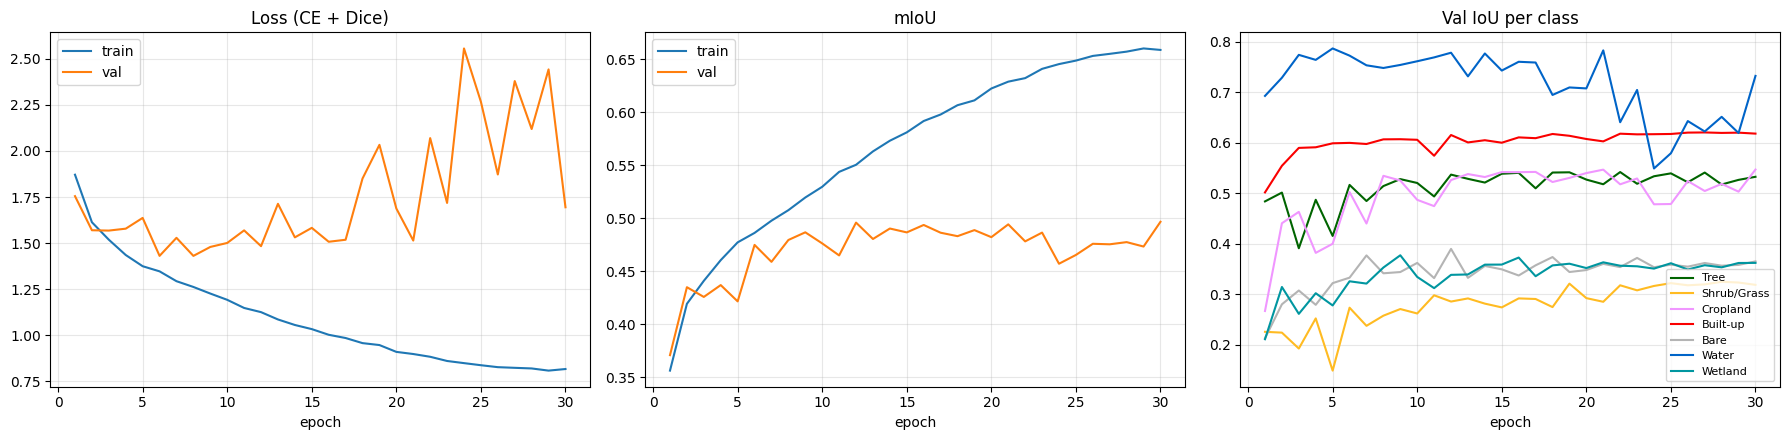

best val mIoU: 0.497 at epoch 30


In [ ]:
h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val")
ax[0].set_title("Loss (CE + Dice)"); ax[0].legend()
ax[1].plot(h.epoch, h.train_miou, label="train"); ax[1].plot(h.epoch, h.val_miou, label="val")
ax[1].set_title("mIoU"); ax[1].legend()
for c in CLASSES:
    ax[2].plot(h.epoch, h[f"iou_{c}"], label=c, color=COLORS[CLASSES.index(c)])
ax[2].set_title("Val IoU per class"); ax[2].legend(fontsize=8)
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
plt.tight_layout(); plt.show()
print("best val mIoU:", round(h.val_miou.max(), 3), "at epoch", int(h.val_miou.idxmax()) + 1)

New cell 6.6: archive run 1

In [ ]:
!cp -r "{CKPT_DIR}" "{SRC}/models_run1"
!ls -lh "{SRC}/models_run1"

total 374M
-rw------- 1 root root  94M Oct 27 00:08 best.pth
-rw------- 1 root root 7.6K Oct 27 00:08 history.csv
-rw------- 1 root root 280M Oct 27 00:08 last.pth


Cell 7.1: test metrics

In [ ]:
ck = torch.load(BEST, map_location=DEVICE, weights_only=False)
model.load_state_dict(ck["model"]); model.eval()
print("best epoch:", ck["epoch"], "| val mIoU:", round(ck["val_miou"], 3))

cm = torch.zeros(NC, NC, dtype=torch.long, device=DEVICE)
with torch.no_grad():
    for xb, yb in tqdm(dl["test"]):
        xb = xb.to(DEVICE, memory_format=torch.channels_last); yb = yb.to(DEVICE)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(xb)
        cm = update_cm(cm, out, yb)

c = cm.cpu().numpy().astype(float)
tp = np.diag(c)
prec = tp / c.sum(0).clip(1); rec = tp / c.sum(1).clip(1)
f1 = 2 * prec * rec / (prec + rec).clip(1e-9)
iou = tp / (c.sum(0) + c.sum(1) - tp).clip(1)
report = pd.DataFrame({"IoU": iou, "Precision": prec, "Recall": rec, "F1": f1,
                       "Pixel share %": c.sum(1) / c.sum() * 100}, index=CLASSES).round(3)
print(report)
print(f"\nTEST  mIoU {iou.mean():.3f} | pixel acc {tp.sum() / c.sum():.3f} | macro F1 {f1.mean():.3f}")
report.to_csv(f"{CKPT_DIR}/test_report.csv")

best epoch: 30 | val mIoU: 0.497


  0%|          | 0/168 [00:00<?, ?it/s]

               IoU  Precision  Recall     F1  Pixel share %
Tree         0.575      0.752   0.710  0.731         25.120
Shrub/Grass  0.331      0.524   0.475  0.498         21.260
Cropland     0.502      0.671   0.666  0.668         18.383
Built-up     0.631      0.678   0.902  0.774         12.011
Bare         0.245      0.506   0.321  0.393          4.935
Water        0.792      0.945   0.830  0.884         14.616
Wetland      0.345      0.395   0.734  0.513          3.675

TEST  mIoU 0.489 | pixel acc 0.674 | macro F1 0.637


Cell 7.2: confusion matrix

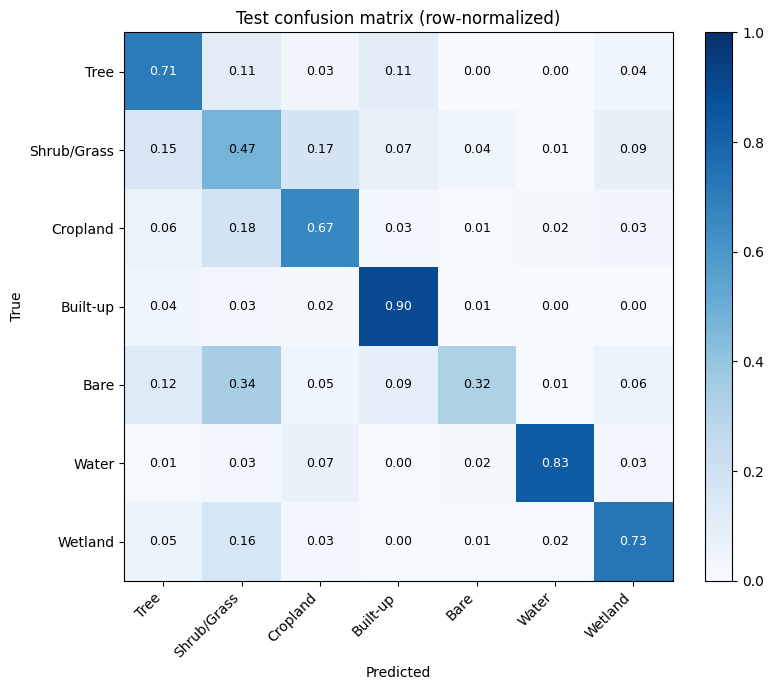

In [ ]:
cmn = c / c.sum(1, keepdims=True).clip(1)
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(NC)); ax.set_xticklabels(CLASSES, rotation=45, ha="right")
ax.set_yticks(range(NC)); ax.set_yticklabels(CLASSES)
for i in range(NC):
    for j in range(NC):
        ax.text(j, i, f"{cmn[i, j]:.2f}", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Test confusion matrix (row-normalized)")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()

Cell 7.3: example predictions

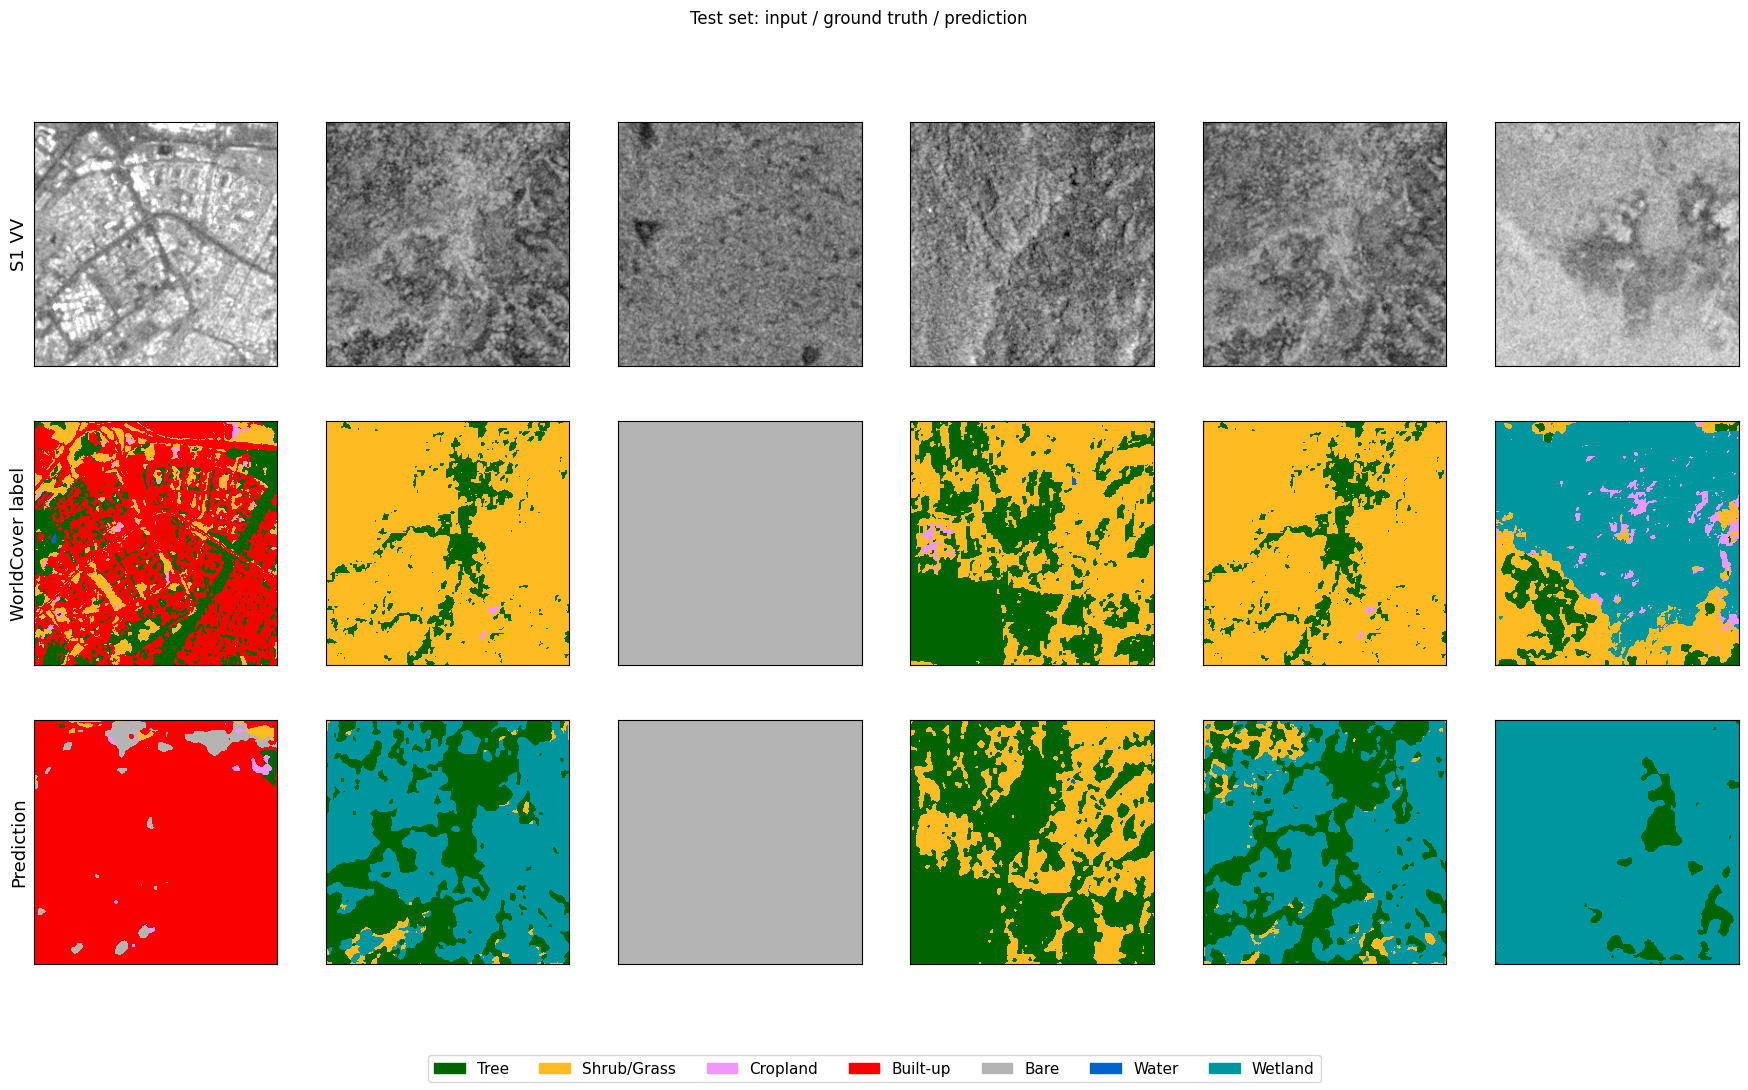

In [ ]:
cmap = ListedColormap(COLORS)
rng = np.random.default_rng(3)
picks = rng.choice(len(ds["test"]), 6, replace=False)
fig, ax = plt.subplots(3, 6, figsize=(22, 11))
with torch.no_grad():
    for k, i in enumerate(picks):
        xi, yi = ds["test"][i]
        with torch.autocast("cuda", dtype=torch.float16):
            pi = model(xi[None].to(DEVICE, memory_format=torch.channels_last)).argmax(1)[0].cpu().numpy()
        ax[0, k].imshow(xi[0], cmap="gray", vmin=-2, vmax=2)
        ax[1, k].imshow(np.ma.masked_equal(yi.numpy(), 255), cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest")
        ax[2, k].imshow(pi, cmap=cmap, vmin=0, vmax=NC - 1, interpolation="nearest")
for r, t in enumerate(["S1 VV", "WorldCover label", "Prediction"]):
    ax[r, 0].set_ylabel(t, fontsize=13)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORS[i]) for i in range(NC)]
fig.legend(handles, CLASSES, loc="lower center", ncol=NC, fontsize=11)
plt.suptitle("Test set: input / ground truth / prediction"); plt.show()